Code: https://github.com/zhurleonid/corporate-risk-management
(`homework_3/part3_var_10day/hw3_part3_code.ipynb`)

Homework 3 comes as three problem sheets; this is sheet 3, numbered Q1 to
Q3 as on the sheet. The write-up is below. The code is appended at
the end. The derivations are handwritten and attached separately: the one-day
loss of the hedged position (set-up), the square-root-of-time rule (Q1), the
re-hedging recursion and its aggregation (Q2), and the reason the rule fails
here (Q3). The write-up points to them where they belong.

# A note on the problem sheet

The sheet says the hedge ratio is $h_t = \partial_s P^{BS}(t, S_t)$ "where
$P^{BS}$ denotes the Black-Scholes call price". The position is a short put,
so I read $P^{BS}$ as the put price. Its delta is $N(d_1) - 1 < 0$, so the
hedge is a short stock position, about 61 shares for 100 puts.

# 10-day VaR of a delta-hedged short put

## Set-up

Short 100 puts with $\kappa = 170$ and $T = 0.292$, hedged with the stock under

$$\frac{dS_t}{S_t} = \mu\,dt + \sigma\,dW_t, \qquad
X_{t+\Delta} = \ln\frac{S_{t+\Delta}}{S_t} \sim N\!\left(\left(\mu - \tfrac12\sigma^2\right)\Delta,\ \sigma^2\Delta\right)$$

with $S_t = 152.51$, $r = 0.119\%$, $\sigma = 49.07\%$, $\mu = 16.91\%$,
$\Delta = 1/252$ and $J = 10$.

> **By hand, attached:** the one-day loss of the hedged position (set-up),
> the square-root-of-time rule (Q1), the daily re-hedging recursion and its
> aggregation (Q2). The pseudocode below implements those expressions.

Time $t$ quantities for 100 puts:

$$P^{BS}(t, S_t) = 27.1077, \qquad \delta = N(d_1) - 1 = -0.6086,$$

$$h_t = 100\,\delta = -60.86 \text{ shares}, \qquad V_t = -2{,}710.77.$$

The hedge is a short of 61 shares, and $V_t$ is minus the premium of the puts.

## Pseudocode (Q1 and Q2)

```
inputs: mu, sigma, r, T, Delta, S0, kappa, M = 100 puts, alpha
        J = 10 days, N = 40,000 runs
m  = (mu - sigma^2/2)*Delta,   s = sigma*sqrt(Delta)
h0 = M * (N(d1(T, S0)) - 1),   V_t = -M * P_BS(T, S0)

Q1, one-day VaR and square-root-of-time:
    draw X_1 ... X_N iid N(m, s^2)
    for each i:
        S1    = S0 * exp(X_i)
        Y_new = 0 - h0*S0
        V1    = h0*S1 + Y_new*exp(r*Delta) - M*P_BS(T - Delta, S1)
        L_i   = V_t - V1
    VaR_1 = sorted L at position ceil(N*alpha) = 38,000
    VaR_sqrt = sqrt(10) * VaR_1

Q2, 10-day VaR with daily re-hedging:
    draw an N x J matrix of X_{i,j} iid N(m, s^2)
    for each path i:
        h = h0,  Y_new = -h0*S0,  S_prev = S0,  V_prev = V_t
        for j = 1 ... J:
            S_j   = S_prev * exp(X_{i,j})
            Y     = Y_new * exp(r*Delta)
            V_j   = Y + h*S_j - M*P_BS(T - j*Delta, S_j)
            l_j   = V_prev - V_j                   loss over day j
            h_new = M * (N(d1(T - j*Delta, S_j)) - 1)   re-hedge
            Y_new = Y + (h - h_new)*S_j            cash pays the trade
            h, S_prev, V_prev = h_new, S_j, V_j
        L_i = l_1 + ... + l_J                      = V_t - V_J
    VaR_10 = sorted L at position 38,000

reference: same paths, hedge frozen at h0 for all ten days
```

The one-day and ten-day runs use separate draws from the same seeded
generator, so the first day of the ten-day paths is not the one-day sample;
the two one-day loss distributions agree to within Monte Carlo noise.

## Q1 and Q2. Results

$$\begin{array}{l r r r r}
\hline
 & \text{VaR}_{0.95} & \text{mean} & \text{s.d.} & \text{skewness} \\
\hline
\text{Q1: one-day loss} & 29.80 & -0.02 & 14.86 & 2.83 \\
\text{Q1: } \sqrt{10} \times \text{one-day VaR} & 94.24 & & & \\
\text{Q2: 10-day loss, re-hedged daily} & 88.62 & 0.11 & 48.00 & 0.89 \\
\text{reference: 10-day loss, hedge frozen at } t & 306.41 & 0.85 & 156.61 & 3.02 \\
\hline
\end{array}$$

*Monte Carlo with 40,000 runs, in dollars, 100 puts.*

## Q3. Comparison

> **Q3: the reason for the difference by hand, attached**, including the
> frozen-hedge contrast.

**The square-root-of-time rule overstates the 10-day VaR by 6%.** The
time-aggregated estimate is 88.62 against 94.24 from scaling, a ratio of
0.940; the attached argument predicts 0.925. This is the same pattern as the
lecture's hedged call, 87.66 against 90.96.

The simulated shape statistics in the table are what the argument relies on.
From one day to ten the standard deviation scales with $\sqrt{10}$ to within
2%, while the skewness falls from 2.83 to 0.89 and the distribution loses its
one-sided shape, as the left panel of the figure shows. Both means are within a dollar of zero, so the drift plays
no part in the gap.

**Re-hedging daily is what makes the 10-day number small at all.** With the
hedge frozen at $t$ for ten days, which is the Homework 2 set-up, the
$\text{VaR}_{0.95}$ on the same paths is 306.41, three and a half times the
re-hedged figure and close to the 304.52 found there; the attached argument
predicts a ratio of 3.4. The right panel of the figure shows the
frozen-hedge distribution as a spike at the theta floor with a tail reaching
past 400, against the re-hedged distribution's near-bell shape.

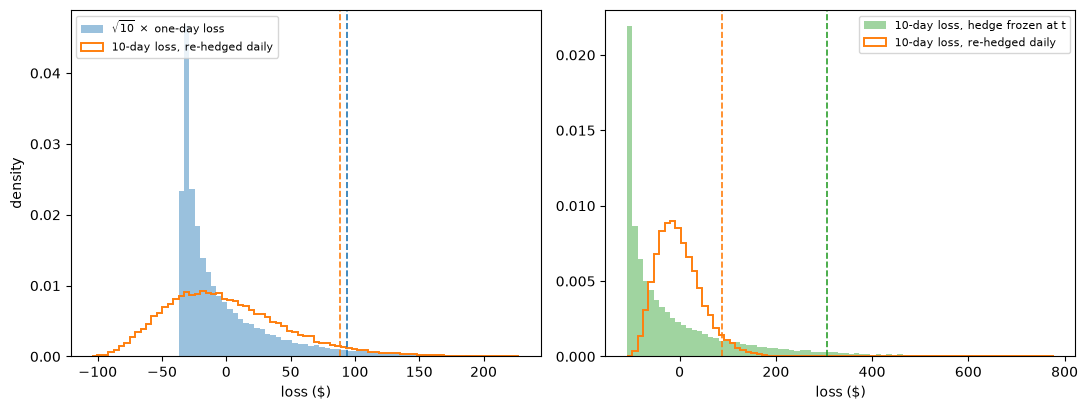

*Left: $\sqrt{10}$ times the one-day loss against the ten-day loss with daily re-hedging, with the two $\text{VaR}_{0.95}$ estimates as dashed lines. Right: the ten-day loss with the hedge frozen at $t$ against the re-hedged one, on the same 40,000 paths. The top 0.5% is cut off in both panels.*